# Pricing and hedging a worst-of autocallable note

A worst-of autocallable is one of the most widely sold structured products. This notebook prices one on the
**S&P 500, Euro Stoxx 50 and Nikkei 225** with Monte Carlo, explains what drives its value, shows the issuer's margin
and the fair coupon, and looks at how the desk would hedge it.

**The note** (notional 100, issued at 100):
- 3 years, observed every quarter (12 dates). Performance of each index = level / starting level; the note looks only
  at the **worst** of the three.
- **Autocall:** on any observation date, if the worst performance is at or above 100%, the note repays 100 plus the
  coupon and ends.
- **Coupon:** paid on a date if the worst performance is at or above 70%; missed coupons are paid later if the
  condition is met again (memory).
- **Capital at risk:** if the note is never called and the worst performance at maturity is below 60%, the investor
  receives 100 x worst performance; otherwise 100.

All numbers below are computed when the notebook runs, from market data cached in `data/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))
from autocall import market as M

ACCENT, GREYS = "#1F4E79", ["#7F8C9A", "#B8C2CC"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5})
pct = lambda x, d=1: "–" if pd.isna(x) else f"{100 * x:.{d}f}%"  # noqa: E731

## 1. Market data

Daily closes from Yahoo Finance for the three indices, the 13-week US Treasury bill yield (for discounting) and the
dividend yields of an ETF tracking each index. The data are cached in `data/` with the date they were fetched.

In [2]:
prices, meta = M.load_prices(), M.load_meta()
closes = M.common_closes(prices)
rets = M.log_returns(closes)
print(f"Fetched on {meta['fetched_on']} from {meta['source']}")
print(f"Prices from {closes.index[0]:%d-%b-%Y} to {closes.index[-1]:%d-%b-%Y} (as of date for pricing)")
M.calendar_gaps(prices)

Fetched on 2026-11-05 from Yahoo Finance via yfinance
Prices from 01-Oct-2021 to 04-Nov-2026 (as of date for pricing)


,own trading days,missing on union calendar,days kept (common)
S&P 500,1279,46,1173
Euro Stoxx 50,1281,44,1173
Nikkei 225,1244,81,1173


**Holidays differ.** The US, Europe and Japan close on different days, so the union calendar has gaps. Volatility and
correlation use only days when all three markets traded; a return then simply spans the holiday.

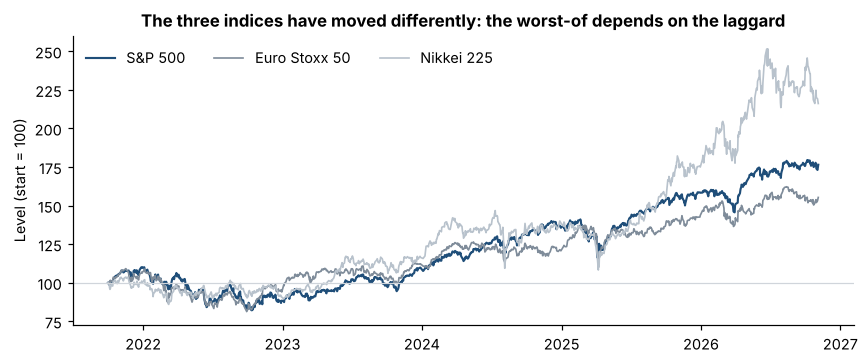

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
rebased = 100 * closes / closes.iloc[0]
for col, c in zip(rebased.columns, [ACCENT] + GREYS):
    ax.plot(rebased.index, rebased[col], color=c, lw=1.4 if c == ACCENT else 1.1, label=col)
ax.axhline(100, color="#D0D5DB", lw=0.8)
ax.set(title="The three indices have moved differently: the worst-of depends on the laggard",
       ylabel="Level (start = 100)")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout()

### Volatility

Three estimates from daily log returns, and one from the option market:
- **historical (full sample)** and **historical (last year)**: annualised standard deviation;
- **EWMA** (RiskMetrics, lambda 0.94): weights recent days more, so it reacts fast;
- **implied** (S&P 500 only): read from at-the-money S&P 500 options expiring close to the note's maturity.

In [4]:
vols = pd.DataFrame({
    "historical, full sample": M.historical_vol(rets),
    "historical, last year": M.historical_vol(rets, M.TRADING_DAYS),
    "EWMA (latest)": M.ewma_vol(rets).iloc[-1],
})
imp = meta.get("spx_implied")
if imp:
    vols.loc["S&P 500", f"implied, {imp['years']:.1f}y ATM"] = imp["atm_iv"]
vols.map(pct).rename_axis("annualised volatility")

,"historical, full sample","historical, last year",EWMA (latest),"implied, 3.1y ATM"
annualised volatility,,,,
S&P 500,17.3%,13.2%,11.8%,19.5%
Euro Stoxx 50,18.0%,15.4%,13.7%,–
Nikkei 225,24.2%,29.8%,25.8%,–


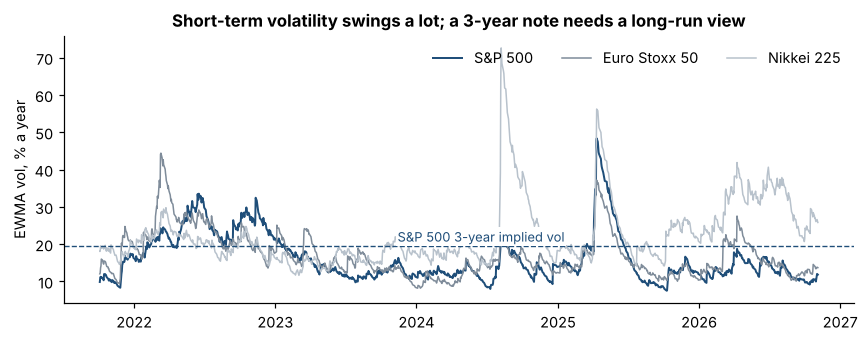

In [5]:
ew = M.ewma_vol(rets)
fig, ax = plt.subplots(figsize=(8, 3.2))
for col, c in zip(ew.columns, [ACCENT] + GREYS):
    ax.plot(ew.index, 100 * ew[col], color=c, lw=1.3 if c == ACCENT else 1.0, label=col)
if imp:
    ax.axhline(100 * imp["atm_iv"], color=ACCENT, ls="--", lw=0.9)
    ax.text(ew.index[int(len(ew) * 0.42)], 100 * imp["atm_iv"] + 1.2, f"S&P 500 {imp['years']:.0f}-year implied vol",
            color=ACCENT, fontsize=8.5, bbox=dict(fc="white", ec="none", pad=1))
ax.set(title="Short-term volatility swings a lot; a 3-year note needs a long-run view", ylabel="EWMA vol, % a year")
ax.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout()

In [6]:
spx = vols.loc["S&P 500"]
print(f"S&P 500: EWMA {spx['EWMA (latest)']:.1%}, full-sample historical {spx['historical, full sample']:.1%}"
      + (f", {imp['years']:.1f}-year implied {imp['atm_iv']:.1%}" if imp else ""))
print("Pricing default: full-sample historical vol. It is the closest of the history-based estimates to the long-dated")
print("implied vol, while the latest EWMA reflects only the last few calm or stressed weeks.")

S&P 500: EWMA 11.8%, full-sample historical 17.3%, 3.1-year implied 19.5%
Pricing default: full-sample historical vol. It is the closest of the history-based estimates to the long-dated
implied vol, while the latest EWMA reflects only the last few calm or stressed weeks.


### Correlation, and why the closing times matter

The worst-of payoff depends heavily on how the indices move together. Tokyo closes before Europe opens, and Europe
closes before New York does, so news that hits the US on day *t* reaches the Nikkei only on day *t + 1*. Same-day
returns therefore understate the true co-movement. Longer return horizons fix most of this.

In [7]:
pairs = [("S&P 500", "Euro Stoxx 50"), ("S&P 500", "Nikkei 225"), ("Euro Stoxx 50", "Nikkei 225")]
corr_tab = pd.DataFrame({f"{h}-day returns": [M.correlation(rets, h).loc[a, b] for a, b in pairs] for h in (1, 2, 5)},
                        index=[f"{a} / {b}" for a, b in pairs])
corr_tab.round(2)

,1-day returns,2-day returns,5-day returns
S&P 500 / Euro Stoxx 50,0.50,0.60,0.70
S&P 500 / Nikkei 225,0.16,0.45,0.62
Euro Stoxx 50 / Nikkei 225,0.33,0.48,0.60


In [8]:
ll = M.lead_lag_correlation(rets, "Nikkei 225", "S&P 500")
print(f"Nikkei vs S&P 500, same day: {ll['same day']:.2f}; Nikkei on the next day vs S&P 500: {ll['Nikkei 225 next day']:.2f}")
print("The Nikkei reacts a day later to US news, so the model uses weekly (5-day) return correlations.")

Nikkei vs S&P 500, same day: 0.16; Nikkei on the next day vs S&P 500: 0.47
The Nikkei reacts a day later to US news, so the model uses weekly (5-day) return correlations.


In [9]:
snap = M.snapshot()
ok, eig = M.is_positive_definite(snap.corr)
print(f"Correlation matrix used for pricing (weekly returns, full sample). Eigenvalues {np.round(eig, 3)}:",
      "positive definite, so a Cholesky factor exists." if ok else "NOT positive definite.")
pd.DataFrame(snap.corr, index=snap.names, columns=snap.names).round(3)

Correlation matrix used for pricing (weekly returns, full sample). Eigenvalues [0.299 0.422 2.279]: positive definite, so a Cholesky factor exists.


,S&P 500,Euro Stoxx 50,Nikkei 225
S&P 500,1.000,0.700,0.616
Euro Stoxx 50,0.700,1.000,0.601
Nikkei 225,0.616,0.601,1.000


### Rates and dividends

In [10]:
inputs = pd.DataFrame({"spot (as of)": [f"{x:,.2f}" for x in snap.spot], "vol": [pct(v) for v in snap.vol],
                       "dividend yield": [pct(v, 2) for v in snap.div]}, index=snap.names)
inputs["dividend source"] = [f"{v['etf']} trailing yield" for v in meta["dividend_yields"].values()]
print(f"USD rate: {snap.rate:.2%} continuously compounded, from the 13-week T-bill yield on {snap.notes['rate_date']}")
inputs

USD rate: 3.95% continuously compounded, from the 13-week T-bill yield on 2026-11-04


,spot (as of),vol,dividend yield,dividend source
S&P 500,"7,688.62",17.3%,1.00%,SPY trailing yield
Euro Stoxx 50,"6,265.71",18.0%,2.81%,FEZ trailing yield
Nikkei 225,"62,188.63",24.2%,1.17%,1321.T trailing yield
